# Challenge 2 — Minería de asteroides
## Pipeline 1: razonamiento, espacio de estados, exploración, búsqueda y resultados
**Curso:** Machine Learning — UPCH  
**Caso:** minería de asteroides (examen parcial)  
**Naturaleza:** modelo didáctico con escenarios **SINTÉTICOS**; no constituye una evaluación real de rentabilidad.

Este notebook sigue la rúbrica: **Problema → Espacio de Estados → Exploración → Búsqueda → Resultado**. Implementa **BFS, DFS y búsqueda exhaustiva (Brute Force, BF)**, técnicas trabajadas en las sesiones 3 y 4. Se aplica razonamiento **deductivo** mediante reglas `si-entonces`.

**Cómo usarlo:** ejecuta todas las celdas de arriba abajo. En la sección *Exploración* cambia `ESCENARIO_ELEGIDO` y `OBJETIVO_ELEGIDO` para experimentar. Los datos JSON se cargan desde la carpeta `data/` de tu repositorio público en GitHub; no necesitas subirlos manualmente a Colab (sí necesitas conexión a Internet).

## 1. Problema

La NASA distingue las misiones científicas de exploración y obtención de muestras de la explotación comercial de asteroides, que todavía plantea desafíos técnicos [1].

**Pregunta:** ¿Cómo explorar rutas de evaluación para recomendar una estrategia de inversión en minería de asteroides, dadas restricciones de información, recursos, tecnología, economía y regulación?

- **Situación inicial:** existe una oportunidad de inversión potencial (S0).
- **Objetivos posibles:** S15 (ampliar investigación), S16 (inversión gradual en I+D) y S17 (postergar inversión).
- **Objetivo específico para comparar BFS y DFS:** por defecto se busca S16 en el escenario favorable. Se puede cambiar.
- **Acciones:** recopilar, analizar recursos, revisar factibilidad técnica, evaluar economía, riesgos y prueba piloto, y formular una recomendación.
- **Restricción clave:** sin información sobre un criterio, el modelo **no permite avanzar** ni fabrica una respuesta.

**Justificación:** la IA simbólica modela estados y aplica reglas explícitas; los algoritmos de búsqueda exploran rutas válidas. Los datos económicos predictivos se estudiarán **en el Pipeline 2** con modelos de regresión.

*Origen de la estructura:* rúbrica Challenge 1 (Pipeline de Machine Learning), sesiones 1–4 del profesor Yannick Carrasco e infografía del examen parcial. Las 18 configuraciones y 28 transiciones son una **formalización experimental diseñada para el challenge**, no un procedimiento oficial espacial.

## 2. Espacio de estados y reglas de razonamiento

La representación de problemas mediante estados, acciones y objetivos es un enfoque clásico de Inteligencia Artificial [2].


Formalmente, el modelo se representa por **\(P=(S,A,T,s_0,G)\)**, donde:

- \(S\): conjunto finito de estados (18 estados, S0–S17).
- \(A\): operadores (recopilar, evaluar, estudiar, postergar, etc.).
- \(T\): 28 transiciones dirigidas con condiciones de habilitación.
- \(s_0=S0\): estado inicial.
- \(G=\{S15,S16,S17\}\): estados terminales posibles.

**Razonamiento deductivo:** si una condición del escenario coincide con una guarda de transición, se permite esa acción. De lo contrario, la transición permanece bloqueada. No se infiere automáticamente que una alternativa sea económicamente óptima.

In [ ]:
# 2. Cargar los datos del repositorio GitHub
import requests
import json
from collections import deque
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

url = "https://raw.githubusercontent.com/pao25-ing/Machine_Learning/main/Challenge_2/data/"

modelo = requests.get(url + "espacio_estados_condiciones.json").json()
datos_escenarios = requests.get(url + "escenarios_asteroides.json").json()
escenarios = datos_escenarios["escenarios"]

print("Estados:", len(modelo["estados"]))
print("Transiciones:", len(modelo["transiciones"]))
print("Escenarios sintéticos:", len(escenarios))


In [2]:
# Revisar estados y transiciones declarados.
filas_estados = [
    {"Código": clave, "Nombre del estado": valor["nombre"],
     "Estado final": "Sí" if valor["terminal"] else "No"}
    for clave, valor in modelo["estados"].items()
]
print("TABLA DE ESTADOS")
display(pd.DataFrame(filas_estados))

filas_transiciones = [
    {"ID": t["id"], "Origen": t["origen"], "Destino": t["destino"],
     "Operador": t["operador"], "Condición": t["precondicion"]}
    for t in modelo["transiciones"]
]
print("OPERADORES Y TRANSICIONES")
display(pd.DataFrame(filas_transiciones))

TABLA DE ESTADOS


,Código,Nombre del estado,Estado final
0,S0,Oportunidad identificada,No
1,S1,Información preliminar revisada,No
2,S2,Evidencia insuficiente,No
3,S3,Evidencia suficiente,No
4,S4,Recursos prometedores,No
5,S5,Potencial mineral no sustentado,No
6,S6,Tecnología factible (escenario),No
7,S7,Limitaciones tecnológicas,No
8,S8,Escenario económico favorable,No
9,S9,Escenario económico desfavorable,No


OPERADORES Y TRANSICIONES


,ID,Origen,Destino,Operador,Condición
0,T01,S0,S1,Recopilar información,Se inicia la revisión documental
1,T02,S1,S2,Verificar evidencias,Información insuficiente
2,T03,S1,S3,Verificar evidencias,Información suficiente según criterios del modelo
3,T04,S2,S3,Ampliar investigación,Se obtiene evidencia adicional suficiente
4,T05,S2,S15,Recomendar investigación,No se obtiene evidencia suficiente
5,T06,S3,S4,Evaluar recursos,Se sustenta un potencial mineral prometedor
6,T07,S3,S5,Evaluar recursos,No se sustenta el potencial mineral
7,T08,S5,S15,Recomendar investigación,Puede investigarse el recurso
8,T09,S5,S17,Postergar,No hay condiciones para continuar
9,T10,S4,S6,Evaluar tecnología,Factibilidad técnica apoyada por evidencia


### 2.1. Validación de los operadores
Las *guardas* expresan precondiciones. Un dato ausente no equivale a `False` ni a un resultado desfavorable: significa **información pendiente**. Las restricciones R1–R8 están descritas en el documento del paso 5.

In [3]:
# Comprobación sencilla de los estados y operadores.
errores = 0
for transicion in modelo["transiciones"]:
    origen = transicion["origen"]
    destino = transicion["destino"]
    if origen not in modelo["estados"] or destino not in modelo["estados"]:
        print("Revisar transición:", transicion["id"])
        errores += 1

if errores == 0:
    print("Los estados y transiciones están correctamente conectados.")

# Regla SI-ENTONCES: comprobar cuándo se puede utilizar una transición.
def cumple_regla(regla, datos):
    if regla["tipo"] == "siempre":
        return True

    campo = regla["campo"]
    if campo not in datos or datos[campo] is None:
        return False  # No tenemos información suficiente.

    if regla["tipo"] == "igual":
        return datos[campo] == regla["valor"]
    if regla["tipo"] == "en":
        return datos[campo] in regla["valores"]
    return False

# Identificar los siguientes estados que cumplen las condiciones.
def sucesores_validos(estado, datos):
    opciones = []
    for transicion in modelo["transiciones"]:
        if transicion["origen"] == estado:
            if cumple_regla(transicion["guarda"], datos):
                opciones.append(transicion)
    return opciones

print("Reglas de razonamiento listas.")

Los estados y transiciones están correctamente conectados.
Reglas de razonamiento listas.


## 3. Exploración de alternativas

Selecciona un escenario **hipotético**. El escenario favorable habilita dos opciones: financiamiento gradual de **investigación y desarrollo** (S16) o una **prueba piloto hipotética** que, si resulta favorable, también conduce a S16. Son *acciones alternativas*, no resultados contradictorios.

- Para BFS/DFS, se define un **estado objetivo específico**.
- Para BF, se enumeran **todas las rutas simples** hasta cualquier estado terminal habilitado.
- Si faltan datos, se identifican rutas **pendientes**, sin emitir conclusiones.

In [4]:
#@title Escenario experimental y objetivo de búsqueda
ESCENARIO_ELEGIDO = "favorable_dos_estrategias" #@param ["favorable_dos_estrategias", "evidencia_insuficiente", "problema_tecnologico", "economia_desfavorable", "piloto_desfavorable_revisable", "datos_incompletos"]
OBJETIVO_ELEGIDO = "S16" #@param ["S15", "S16", "S17"]

info = escenarios[ESCENARIO_ELEGIDO]
variables = info["variables"]
estado_inicial = modelo["estado_inicial"]
if OBJETIVO_ELEGIDO not in modelo["estados_objetivo"]:
    print("El objetivo seleccionado no es un estado final.")

print("ESCENARIO:", ESCENARIO_ELEGIDO)
print("Descripción:", info["descripcion"])
print("OBJETIVO:", OBJETIVO_ELEGIDO, "-", modelo["estados"][OBJETIVO_ELEGIDO]["nombre"])
print("Valores sintéticos declarados:")
display(pd.DataFrame([{"Variable": k, "Valor": str(v)} for k, v in variables.items()]))

habilitadas = [t for t in modelo["transiciones"] if cumple_regla(t["guarda"], variables)]
print(f"Transiciones habilitadas: {len(habilitadas)} de {len(modelo['transiciones'])}")
display(pd.DataFrame([{"ID": t["id"], "Origen": t["origen"], "Destino": t["destino"], "Operador": t["operador"]} for t in habilitadas]))

ESCENARIO: favorable_dos_estrategias
Descripción: Supuesto favorable con posibilidad de I+D gradual o prueba piloto; se pueden explorar ambas rutas.
OBJETIVO: S16 - Decisión: inversión gradual
Valores sintéticos declarados:


,Variable,Valor
0,evidencia_inicial,suficiente
1,potencial_recursos,prometedor
2,factibilidad_tecnica,factible
3,viabilidad_economica,favorable
4,condiciones_legal_riesgo,aceptables
5,opcion_inversion,ambas
6,resultado_piloto,favorable


Transiciones habilitadas: 10 de 28


,ID,Origen,Destino,Operador
0,T01,S0,S1,Recopilar información
1,T03,S1,S3,Verificar evidencias
2,T06,S3,S4,Evaluar recursos
3,T10,S4,S6,Evaluar tecnología
4,T14,S6,S8,Evaluar economía
5,T18,S8,S10,Evaluar marco legal y riesgos
6,T22,S10,S12,Planificar prueba piloto
7,T23,S10,S16,Decidir inversión gradual
8,T24,S12,S13,Evaluar prueba piloto
9,T26,S13,S16,Decidir inversión gradual


## 4. Búsqueda: BFS, DFS y BF

Los recorridos sistemáticos de estados permiten comparar estrategias de exploración de soluciones [2].


**BFS (cola FIFO):** devuelve una ruta con mínimo número de transiciones hacia el objetivo elegido si las aristas no tienen pesos.  
**DFS (pila LIFO):** se interna primero en una rama; la primera ruta encontrada depende del orden de sucesores.  
**BF (exhaustiva):** enumera todas las rutas simples habilitadas hasta estados terminales y las compara; no se inventan costos ni una función económica de optimización.

**Diferencia importante:** `BF` (*Brute Force*) **no** es `BFS` (*Breadth-First Search*).

In [5]:
# BFS: utiliza una cola y explora primero los estados cercanos.
def bfs(inicio, objetivo, datos):
    cola = deque([[inicio]])
    visitados = [inicio]
    explorados = []

    while cola:
        ruta = cola.popleft()
        estado = ruta[-1]
        explorados.append(estado)

        if estado == objetivo:
            return {"ruta": ruta, "explorados": explorados}

        for transicion in sucesores_validos(estado, datos):
            siguiente = transicion["destino"]
            if siguiente not in visitados:
                visitados.append(siguiente)
                cola.append(ruta + [siguiente])

    return {"ruta": None, "explorados": explorados}


# DFS: utiliza una pila y explora primero una rama completa.
def dfs(inicio, objetivo, datos):
    pila = [[inicio]]
    visitados = []
    explorados = []

    while pila:
        ruta = pila.pop()
        estado = ruta[-1]

        if estado not in visitados:
            visitados.append(estado)
            explorados.append(estado)

            if estado == objetivo:
                return {"ruta": ruta, "explorados": explorados}

            opciones = sucesores_validos(estado, datos)
            for transicion in reversed(opciones):
                siguiente = transicion["destino"]
                if siguiente not in visitados and siguiente not in ruta:
                    pila.append(ruta + [siguiente])

    return {"ruta": None, "explorados": explorados}


# BF: revisar todas las rutas simples, sin repetir estados en una ruta.
def bf_exhaustiva(inicio, datos):
    pila = [[inicio]]
    completas = []
    pendientes = []
    evaluados = []

    while pila:
        ruta = pila.pop()
        estado = ruta[-1]
        evaluados.append(estado)

        if modelo["estados"][estado]["terminal"]:
            completas.append(ruta)
        else:
            opciones = []
            for transicion in sucesores_validos(estado, datos):
                if transicion["destino"] not in ruta:
                    opciones.append(transicion["destino"])

            if not opciones:
                pendientes.append(ruta)
            else:
                for siguiente in reversed(opciones):
                    pila.append(ruta + [siguiente])

    return {"rutas": completas, "pendientes": pendientes, "evaluados": evaluados}

print("BFS, DFS y búsqueda exhaustiva definidos.")

BFS, DFS y búsqueda exhaustiva definidos.


In [6]:
# Comparar algoritmos con el mismo escenario y un objetivo explícito.
resultado_bfs = bfs(estado_inicial, OBJETIVO_ELEGIDO, variables)
resultado_dfs = dfs(estado_inicial, OBJETIVO_ELEGIDO, variables)
resultado_bf = bf_exhaustiva(estado_inicial, variables)

for nombre, resultado in [("BFS", resultado_bfs), ("DFS", resultado_dfs)]:
    print("\n", nombre)
    print("  Exploración:", " → ".join(resultado["explorados"]))
    print("  Estados evaluados:", len(resultado["explorados"]))
    if resultado["ruta"]:
        print("  Ruta al objetivo:", " → ".join(resultado["ruta"]))
        print("  Número de transiciones:", len(resultado["ruta"]) - 1)
    else:
        print("  No se encontró ruta hasta", OBJETIVO_ELEGIDO, "con este escenario.")

print("\nBF (búsqueda exhaustiva)")
for i, ruta in enumerate(resultado_bf["rutas"], start=1):
    print(f"  Ruta {i}:", " → ".join(ruta),
          "| Resultado:", modelo["estados"][ruta[-1]]["nombre"])
for i, ruta in enumerate(resultado_bf["pendientes"], start=1):
    print(f"  Ruta pendiente {i}:", " → ".join(ruta), "| DATOS FALTANTES")
print("  Total rutas terminales:", len(resultado_bf["rutas"]))
print("  Rutas pendientes:", len(resultado_bf["pendientes"]))


 BFS
  Exploración: S0 → S1 → S3 → S4 → S6 → S8 → S10 → S12 → S16
  Estados evaluados: 9
  Ruta al objetivo: S0 → S1 → S3 → S4 → S6 → S8 → S10 → S16
  Número de transiciones: 7

 DFS
  Exploración: S0 → S1 → S3 → S4 → S6 → S8 → S10 → S12 → S13 → S16
  Estados evaluados: 10
  Ruta al objetivo: S0 → S1 → S3 → S4 → S6 → S8 → S10 → S12 → S13 → S16
  Número de transiciones: 9

BF (búsqueda exhaustiva)
  Ruta 1: S0 → S1 → S3 → S4 → S6 → S8 → S10 → S12 → S13 → S16 | Resultado: Decisión: inversión gradual
  Ruta 2: S0 → S1 → S3 → S4 → S6 → S8 → S10 → S16 | Resultado: Decisión: inversión gradual
  Total rutas terminales: 2
  Rutas pendientes: 0


## 5. Resultados comparativos

Como no tenemos costos por transición, **no podemos concluir qué estrategia es la mejor económicamente**. Podemos comparar longitud de rutas y trabajo de exploración. BF revisa todas las rutas, por lo que cuenta **evaluaciones de estados por ruta** y puede repetir estados compartidos. BFS y DFS cuentan estados extraídos de sus respectivas estructuras de búsqueda hasta encontrar el objetivo (o agotar las opciones).

In [7]:
filas = []
for nombre, resultado in [("BFS", resultado_bfs), ("DFS", resultado_dfs)]:
    ruta = resultado["ruta"]
    filas.append({
        "Algoritmo": nombre,
        "Estados evaluados": len(resultado["explorados"]),
        "Rutas terminales enumeradas": 1 if ruta else 0,
        "Transiciones de la ruta": len(ruta) - 1 if ruta else None,
        "Ruta encontrada": " → ".join(ruta) if ruta else "Sin ruta al objetivo",
    })
filas.append({
    "Algoritmo": "BF (exhaustiva)",
    "Estados evaluados": len(resultado_bf["evaluados"]),
    "Rutas terminales enumeradas": len(resultado_bf["rutas"]),
    "Transiciones de la ruta": None, # BF enumera varias rutas, no una única
    "Ruta encontrada": f"{len(resultado_bf['rutas'])} terminal(es); {len(resultado_bf['pendientes'])} pendiente(s)",
})
comparacion = pd.DataFrame(filas)
display(comparacion)

# Interpretar las rutas encontradas (sin utilizar assert).
if ESCENARIO_ELEGIDO == "favorable_dos_estrategias" and OBJETIVO_ELEGIDO == "S16":
    print("Escenario favorable:")
    print("- Transiciones encontradas por BFS:", len(resultado_bfs["ruta"]) - 1)
    print("- Transiciones encontradas por DFS:", len(resultado_dfs["ruta"]) - 1)
    print("- Rutas completas encontradas por BF:", len(resultado_bf["rutas"]))

if resultado_bf["pendientes"]:
    print("AVISO: hay información pendiente. No convertir el estado incompleto en una decisión final.")

,Algoritmo,Estados evaluados,Rutas terminales enumeradas,Transiciones de la ruta,Ruta encontrada
0,BFS,9,1,7.0,S0 → S1 → S3 → S4 → S6 → S8 → S10 → S16
1,DFS,10,1,9.0,S0 → S1 → S3 → S4 → S6 → S8 → S10 → S12 → S13 ...
2,BF (exhaustiva),11,2,NaN,2 terminal(es); 0 pendiente(s)


Escenario favorable:
- Transiciones encontradas por BFS: 7
- Transiciones encontradas por DFS: 9
- Rutas completas encontradas por BF: 2


### 5.1. Gráfico del espacio de estados habilitado

- **Azul:** transiciones habilitadas en el escenario.
- **Gris:** transiciones del grafo general que no se pueden usar en ese escenario.
- **Verde:** ruta que encontró BFS hasta el objetivo seleccionado (si existe).

La posición de los nodos es solo una ayuda visual; no representa duración ni costo de misiones.

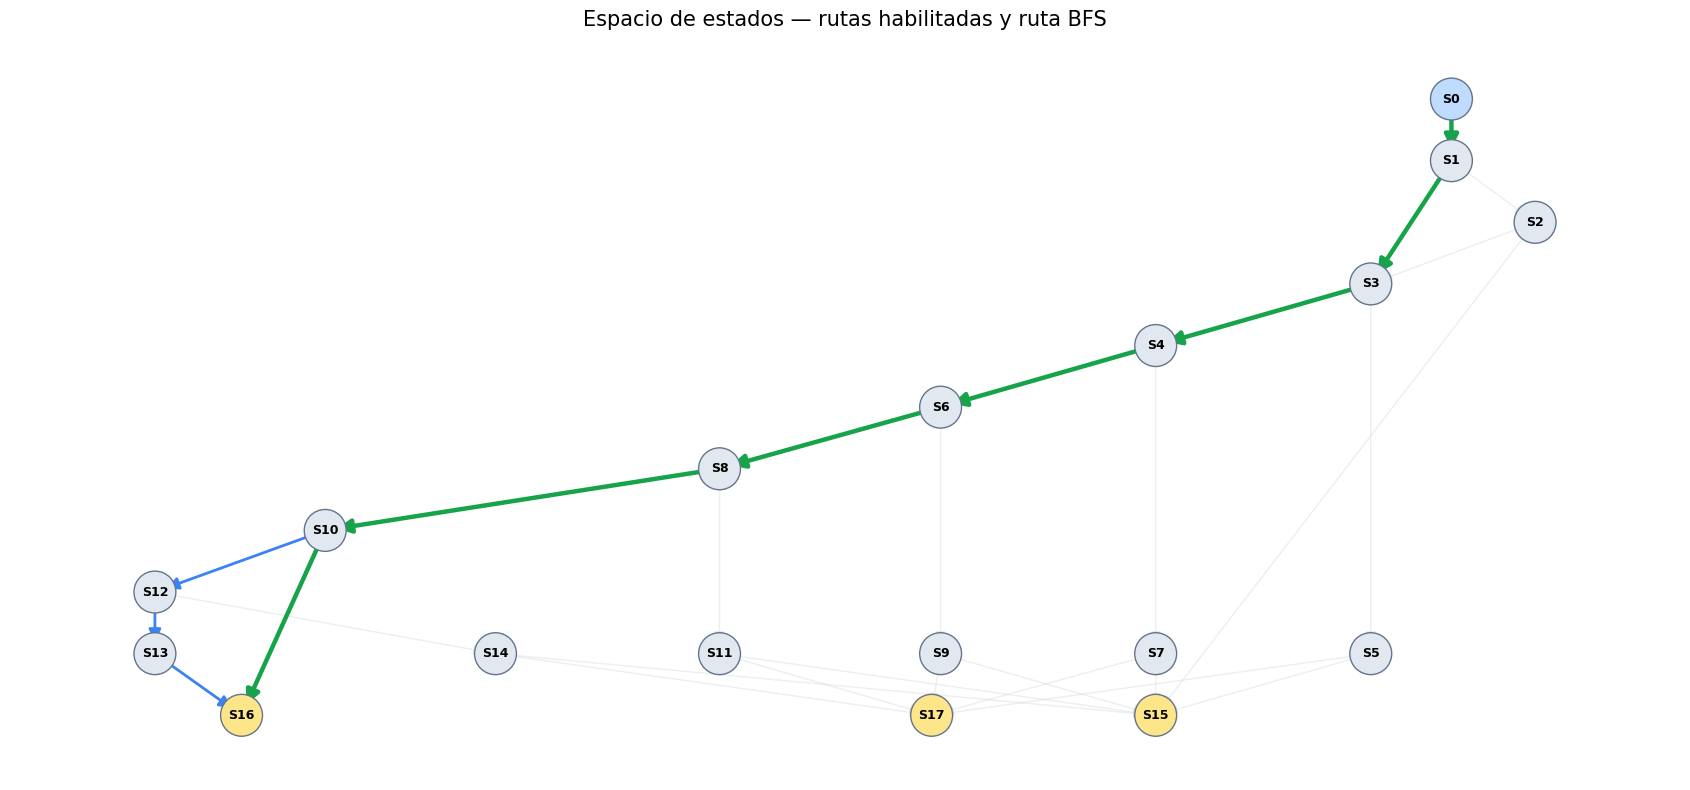

In [8]:
# Dibujar el grafo completo e identificar las transiciones usadas en el escenario.
grafo_total = nx.DiGraph()
for e in modelo["estados"]:
    grafo_total.add_node(e)
for t in modelo["transiciones"]:
    grafo_total.add_edge(t["origen"], t["destino"])

try:
    pos = nx.nx_pydot.graphviz_layout(grafo_total, prog="dot")
except Exception:
    pos = nx.spring_layout(grafo_total, seed=42)

aristas_habilitadas = {(t["origen"], t["destino"]) for t in habilitadas}
aristas_ruta = set(zip(resultado_bfs["ruta"][:-1], resultado_bfs["ruta"][1:])) if resultado_bfs["ruta"] else set()
resto = [e for e in grafo_total.edges if e not in aristas_habilitadas]
activas = [e for e in grafo_total.edges if e in aristas_habilitadas and e not in aristas_ruta]
ruta_resaltada = [e for e in grafo_total.edges if e in aristas_ruta]

fig, ax = plt.subplots(figsize=(17, 8))
colores = []
for e in grafo_total.nodes:
    if e in modelo["estados_objetivo"]:
        colores.append("#fde68a")
    elif e == "S0":
        colores.append("#bfdbfe")
    else:
        colores.append("#e2e8f0")
nx.draw_networkx_nodes(grafo_total, pos, node_size=910, node_color=colores,
                       edgecolors="#64748b", linewidths=1, ax=ax)
nx.draw_networkx_labels(grafo_total, pos, font_size=9, font_weight="bold", ax=ax)
nx.draw_networkx_edges(grafo_total, pos, edgelist=resto, edge_color="#d1d5db",
                       alpha=.4, arrowsize=15, width=1, ax=ax)
nx.draw_networkx_edges(grafo_total, pos, edgelist=activas, edge_color="#3b82f6",
                       arrowsize=18, width=2.0, ax=ax)
nx.draw_networkx_edges(grafo_total, pos, edgelist=ruta_resaltada, edge_color="#16a34a",
                       arrowsize=20, width=3.2, ax=ax)
ax.set_title("Espacio de estados — rutas habilitadas y ruta BFS", fontsize=15)
ax.axis("off")
plt.tight_layout()
plt.savefig("pipeline1_grafo_escenario.png", dpi=180, bbox_inches="tight")
plt.show()

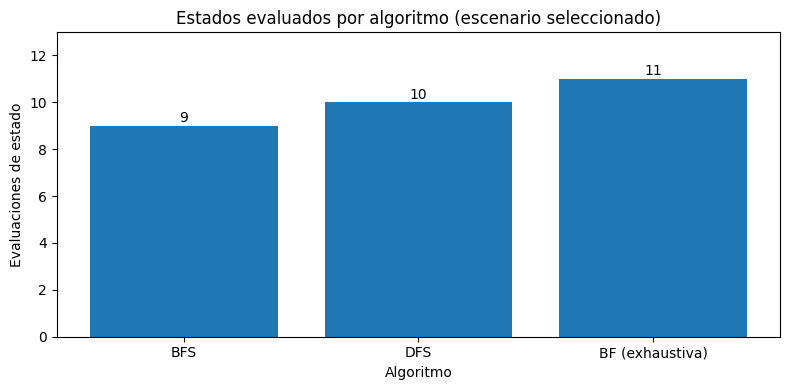

Nota: BF puede contar un estado compartido más de una vez al examinar rutas distintas.


In [9]:
# Visualizar el esfuerzo de búsqueda medido como estados evaluados.
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparacion["Algoritmo"], comparacion["Estados evaluados"])
ax.set_title("Estados evaluados por algoritmo (escenario seleccionado)")
ax.set_ylabel("Evaluaciones de estado")
ax.set_xlabel("Algoritmo")
ax.set_ylim(0, max(comparacion["Estados evaluados"]) * 1.18)
for i, n in enumerate(comparacion["Estados evaluados"]):
    ax.text(i, n + .15, str(n), ha="center")
plt.tight_layout()
plt.savefig("pipeline1_comparacion_algoritmos.png", dpi=180, bbox_inches="tight")
plt.show()
print("Nota: BF puede contar un estado compartido más de una vez al examinar rutas distintas.")

## 6. Evaluar los seis escenarios experimentales

Ejecutamos BF en todos los escenarios para comprobar que existen desenlaces diferentes. Una ruta **pendiente** se distingue de una decisión terminal, especialmente cuando faltan valores.

In [10]:
resumen = []
for clave, registro in escenarios.items():
    resultado = bf_exhaustiva(estado_inicial, registro["variables"])
    resultados = sorted({modelo["estados"][r[-1]]["nombre"] for r in resultado["rutas"]})
    resumen.append({
        "Escenario": clave,
        "Rutas terminales": len(resultado["rutas"]),
        "Rutas pendientes": len(resultado["pendientes"]),
        "Decisiones alcanzadas": ", ".join(resultados) if resultados else "Sin conclusión",
    })
resumen_escenarios = pd.DataFrame(resumen)
display(resumen_escenarios)
# El escenario sin datos suficientes debe mantenerse sin conclusión.
filas_pendientes = resumen_escenarios[resumen_escenarios["Escenario"] == "datos_incompletos"]
if not filas_pendientes.empty:
    print("Datos incompletos: se mantienen las rutas pendientes, sin recomendar una inversión.")

,Escenario,Rutas terminales,Rutas pendientes,Decisiones alcanzadas
0,favorable_dos_estrategias,2,0,Decisión: inversión gradual
1,evidencia_insuficiente,1,0,Decisión: ampliar investigación
2,problema_tecnologico,1,0,Decisión: postergar inversión
3,economia_desfavorable,1,0,Decisión: postergar inversión
4,piloto_desfavorable_revisable,1,0,Decisión: ampliar investigación
5,datos_incompletos,0,1,Sin conclusión


Datos incompletos: se mantienen las rutas pendientes, sin recomendar una inversión.


## 7. Exportación de resultados para GitHub y la web responsive

Se guardan dos JSON: uno con los escenarios y el modelo (para ejecutar las reglas en JavaScript), y otro con los resultados calculados de cada escenario. En GitHub, guarda estos archivos junto a tu web o en `data/`.

In [ ]:
# Guardar datos para usar los resultados en la web responsive
resultado_exportacion = {}

for clave, info in escenarios.items():
    datos = info["variables"]
    rutas = bf_exhaustiva(estado_inicial, datos)
    decisiones = []
    for ruta in rutas["rutas"]:
        if ruta[-1] not in decisiones:
            decisiones.append(ruta[-1])

    resultado_exportacion[clave] = {
        "descripcion": info["descripcion"],
        "rutas_terminales": rutas["rutas"],
        "rutas_pendientes": rutas["pendientes"],
        "decisiones": sorted(decisiones),
        "bfs_hacia_S16": bfs(estado_inicial, "S16", datos),
        "dfs_hacia_S16": dfs(estado_inicial, "S16", datos),
    }

with open("pipeline1_modelo_web.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": modelo, "escenarios": datos_escenarios}, f, ensure_ascii=False, indent=2)

with open("pipeline1_resultados_web.json", "w", encoding="utf-8") as f:
    json.dump({"advertencia": "Resultados experimentales, no inversión real",
               "resultados": resultado_exportacion}, f, ensure_ascii=False, indent=2)

comparacion.to_csv("pipeline1_comparacion.csv", index=False)
print("Archivos generados: pipeline1_modelo_web.json, pipeline1_resultados_web.json,")
print("pipeline1_comparacion.csv, pipeline1_grafo_escenario.png y pipeline1_comparacion_algoritmos.png")


## 8. Interpretación y conclusiones

1. **BFS** busca primero rutas con pocas transiciones y, en un grafo no ponderado, devuelve una ruta mínima en número de aristas hacia el objetivo explícito.
2. **DFS** se interna en la primera rama disponible, por lo que su ruta depende del orden de sucesores y puede ser más larga.
3. **BF** enumera exhaustivamente las rutas simples habilitadas del grafo para comparar diferentes alternativas y descubrir ramas pendientes.
4. Las reglas deductivas evitan avanzar cuando una condición del escenario no está declarada. La ausencia de información **no se interpreta como viabilidad desfavorable**.
5. Ningún algoritmo por sí solo establece la rentabilidad de una inversión. **La menor cantidad de transiciones no equivale al menor costo real.**
6. Los valores de los escenarios son cualitativos y sintéticos. Los avances tecnológicos descritos en la infografía motivan el problema, pero **no validan los desenlaces favorables del simulador**.

### Próximo paso
El **Pipeline 2** elegirá una variable numérica y entrenará un modelo de **regresión lineal o no lineal**, según los datos disponibles y los ejercicios de la sesión 7.

### Referencias (formato IEEE)

[1] NASA, “Is NASA Mining Asteroids? We Asked a NASA Scientist: Episode 41,” 28 jun. 2023. [En línea]. Disponible en: https://www.nasa.gov/general/is-nasa-mining-asteroids-we-asked-a-nasa-scientist-episode-41/. [Accedido: 14-oct-2026].

[2] S. Russell y P. Norvig, *Artificial Intelligence: A Modern Approach*, 4.ª ed. Pearson, 2021.

### Archivos y material del caso

La infografía del examen y los archivos `espacio_estados_condiciones.json` y `escenarios_asteroides.json` se usan como material de partida y elaboración propia, sin incluir los materiales internos del curso como referencias bibliográficas.